In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Walmart.csv")
print("Dataset loaded successfully !")

Dataset loaded successfully !


In [114]:
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


In [116]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

print(df.head())

   Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1 2010-02-05    1643690.90             0        42.31       2.572   
1      1 2010-02-12    1641957.44             1        38.51       2.548   
2      1 2010-02-19    1611968.17             0        39.93       2.514   
3      1 2010-02-26    1409727.59             0        46.63       2.561   
4      1 2010-03-05    1554806.68             0        46.50       2.625   

          CPI  Unemployment  
0  211.096358         8.106  
1  211.242170         8.106  
2  211.289143         8.106  
3  211.319643         8.106  
4  211.350143         8.106  


In [118]:
#selecting data for store 1
store_df = df[df["Store"] == 1].copy()

#sort records by date
store_df = store_df.sort_values("Date")

print(store_df.shape,"\n")
print(store_df.head())

(143, 8) 

   Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1 2010-02-05    1643690.90             0        42.31       2.572   
1      1 2010-02-12    1641957.44             1        38.51       2.548   
2      1 2010-02-19    1611968.17             0        39.93       2.514   
3      1 2010-02-26    1409727.59             0        46.63       2.561   
4      1 2010-03-05    1554806.68             0        46.50       2.625   

          CPI  Unemployment  
0  211.096358         8.106  
1  211.242170         8.106  
2  211.289143         8.106  
3  211.319643         8.106  
4  211.350143         8.106  


In [120]:
#checking missing values
df.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

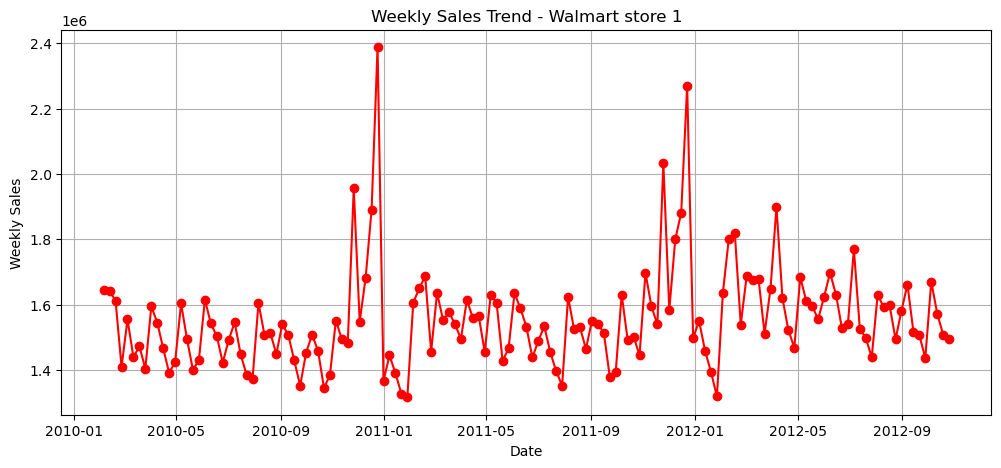

In [122]:
#visualize the dataset
plt.figure(figsize=(12,5))

plt.plot( store_df['Date'], store_df['Weekly_Sales'], marker = "o" , color ="red")
plt.title("Weekly Sales Trend - Walmart store 1")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.grid()
plt.show()

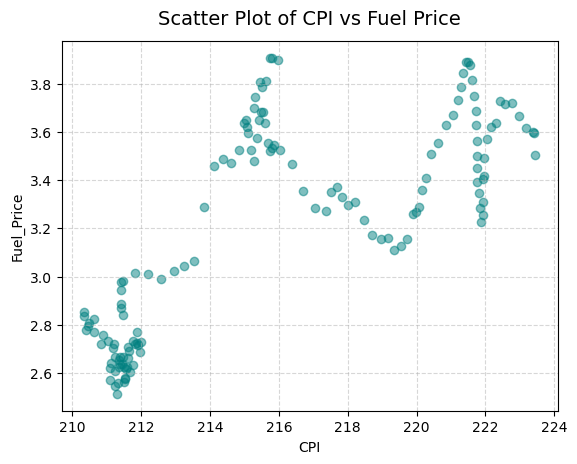

In [124]:
plt.scatter(store_df['CPI'] , store_df['Fuel_Price'] , alpha=0.5, color = 'teal')
plt.xlabel("CPI")
plt.ylabel("Fuel_Price")

plt.title("Scatter Plot of CPI vs Fuel Price", fontsize=14, pad=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


 Holiday_Flag
0    1.546957e+06
1    1.665748e+06
Name: Weekly_Sales, dtype: float64 



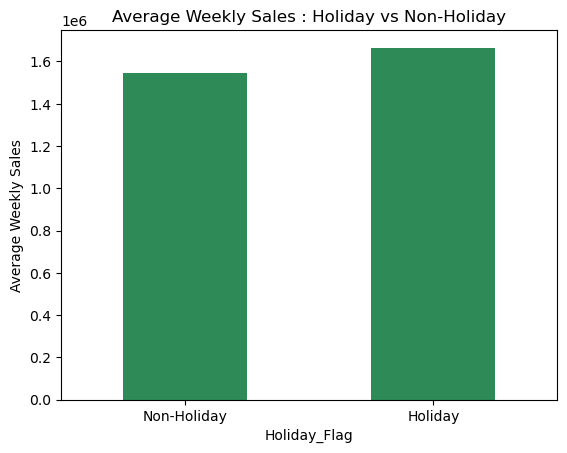

In [126]:
#comparing holiday and non-holiday sales
holiday_sales = store_df.groupby("Holiday_Flag")["Weekly_Sales"].mean()

print("\n",holiday_sales,"\n")

holiday_sales.plot(kind = "bar" , title ="Average Weekly Sales : Holiday vs Non-Holiday" , color="seagreen")
plt.xticks([0 , 1], ["Non-Holiday","Holiday"], rotation = 0)
plt.ylabel("Average Weekly Sales")
plt.show()

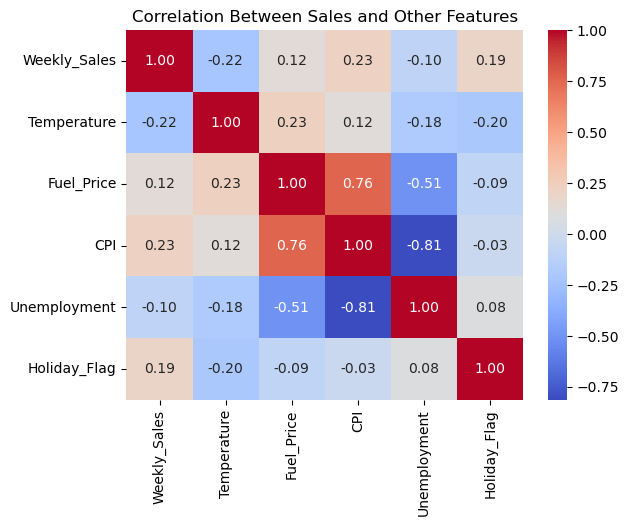

In [128]:
#checking correlation between numerical features
correlation = store_df[["Weekly_Sales", "Temperature" , "Fuel_Price" , "CPI" , "Unemployment" , "Holiday_Flag"]].corr()

sns.heatmap(correlation, annot=True , cmap="coolwarm" , fmt= ".2f")

plt.title("Correlation Between Sales and Other Features")
plt.show()

In [130]:
#Feature engineering
#creating new features from existing feature
store_df["Year"] = store_df["Date"].dt.year
store_df["Month"] = store_df["Date"].dt.month
store_df["Week"] = store_df["Date"].dt.isocalendar().week.astype(int)

#selecting inout features
features = [ "Year" ,"Month" , "Week" , "Holiday_Flag" , "Temperature" , "Fuel_Price" , "CPI" , "Unemployment"]

X=store_df[features]
y=store_df["Weekly_Sales"]

print(X.head())
print("\n\n")
print(y.head())

   Year  Month  Week  Holiday_Flag  Temperature  Fuel_Price         CPI  \
0  2010      2     5             0        42.31       2.572  211.096358   
1  2010      2     6             1        38.51       2.548  211.242170   
2  2010      2     7             0        39.93       2.514  211.289143   
3  2010      2     8             0        46.63       2.561  211.319643   
4  2010      3     9             0        46.50       2.625  211.350143   

   Unemployment  
0         8.106  
1         8.106  
2         8.106  
3         8.106  
4         8.106  



0    1643690.90
1    1641957.44
2    1611968.17
3    1409727.59
4    1554806.68
Name: Weekly_Sales, dtype: float64


In [132]:
#split the dataset
split = int(len(store_df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training records :", len(X_train))
print("Testing records : ", len(X_test))

Training records : 114
Testing records :  29


In [134]:
#Training the models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

#Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train , y_train)

#Random Forest Regression
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Generate predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest predictions generated!")

Random Forest predictions generated!


In [136]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Function to evaluate model
def evaluate_model(y_test, predictions, model_name):
    print(model_name)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("R2 Score:", r2_score(y_test, predictions))
    print()

# Evaluate both models
evaluate_model(y_test, lr_pred, "Linear Regression")
evaluate_model(y_test, rf_pred, "Random Forest Regression")

Linear Regression


ValueError: Found input variables with inconsistent numbers of samples: [29, 27]

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    store_df["Date"],
    store_df["Weekly_Sales"],
    marker="o"
)

plt.title("Weekly Sales Trend - Store 1")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [139]:
# Create lag features
store_df["Previous_Week_Sales"] = (
    store_df["Weekly_Sales"].shift(1)
)

store_df["Previous_4_Week_Sales"] = (
    store_df["Weekly_Sales"].shift(4)
)

# Remove rows with missing lag values
store_df = store_df.dropna().copy()

# Select features
features = [
    "Year",
    "Month",
    "Week",
    "Holiday_Flag",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "Previous_Week_Sales",
    "Previous_4_Week_Sales"
]

X = store_df[features]
y = store_df["Weekly_Sales"]

# Chronological train-test split
split = int(len(store_df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [141]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

# Evaluate
evaluate_model(y_test, lr_pred, "Linear Regression")
evaluate_model(y_test, rf_pred, "Random Forest Regression")

Linear Regression
MAE: 71706.04272933333
RMSE: 87970.43286304094
R2 Score: -0.19370524367320407

Random Forest Regression
MAE: 137514.2048071415
RMSE: 153325.21715376177
R2 Score: -2.6261922103853155



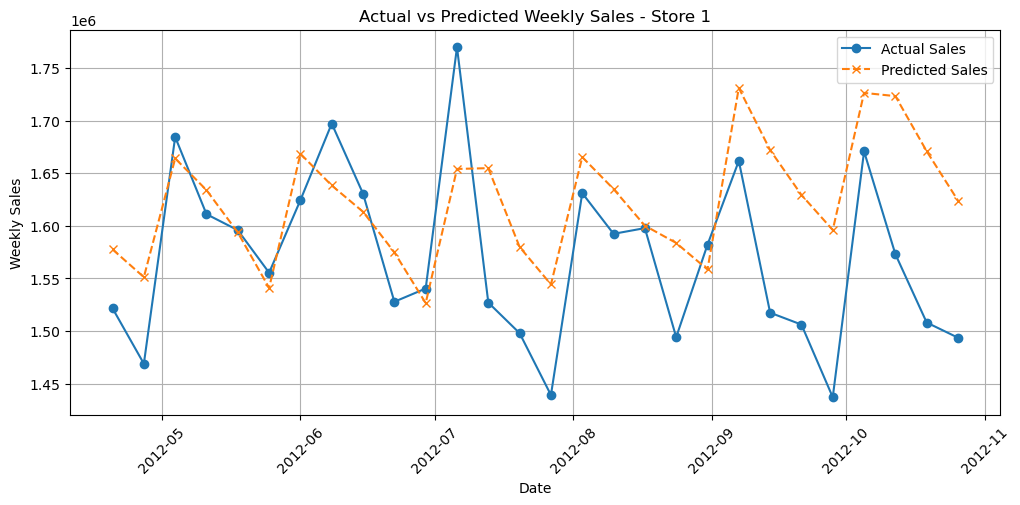

In [143]:
plt.figure(figsize=(12, 5))

plt.plot(
    store_df["Date"].iloc[split:],
    y_test,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    store_df["Date"].iloc[split:],
    lr_pred,
    label="Predicted Sales",
    marker="x",
    linestyle="--"
)

plt.title("Actual vs Predicted Weekly Sales - Store 1")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()

<h2>Time series Forecasting</h2>

In [148]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [156]:
# Select Store 1
arima_df = pd.read_csv("Walmart.csv")

arima_df["Date"] = pd.to_datetime(
    arima_df["Date"], dayfirst=True
)

arima_df = arima_df[arima_df["Store"] == 1]

# Sort by date
arima_df = arima_df.sort_values("Date")

# Set Date as index
sales = arima_df.set_index("Date")["Weekly_Sales"]

# Assign weekly frequency (Friday)
sales = sales.asfreq("W-FRI")

print(sales.head())

Date
2010-02-05    1643690.90
2010-02-12    1641957.44
2010-02-19    1611968.17
2010-02-26    1409727.59
2010-03-05    1554806.68
Freq: W-FRI, Name: Weekly_Sales, dtype: float64


In [158]:
split = int(len(sales) * 0.8)

train = sales.iloc[:split]
test = sales.iloc[split:]

print("Training records:", len(train))
print("Testing records:", len(test))

Training records: 114
Testing records: 29


In [160]:
#building ARIMA model
arima_model = ARIMA(train , order = (1 ,1 ,1))

#train model
arima_result = arima_model.fit()

#predict test data
arima_pred = arima_result.forecast(steps = len(test))

In [162]:
#Evaluate model
print("ARIMA Model ")

print("MAE: ", mean_absolute_error(test ,arima_pred))

print("RMSE: ", np.sqrt(mean_absolute_error(test , arima_pred)))

print("R2 Score : " , r2_score(test , arima_pred))

ARIMA Model 
MAE:  104878.25259697158
RMSE:  323.8491201114673
R2 Score :  -1.3684354699406218


In [166]:
# Convert predictions into array
arima_pred = np.array(arima_pred)

# Calculate evaluation metrics
mae = mean_absolute_error(test, arima_pred)

rmse = np.sqrt(
    mean_squared_error(test, arima_pred)
)

r2 = r2_score(test, arima_pred)

print("ARIMA Model")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

ARIMA Model
MAE: 104878.25259697158
RMSE: 122601.62825219876
R2 Score: -1.3684354699406218


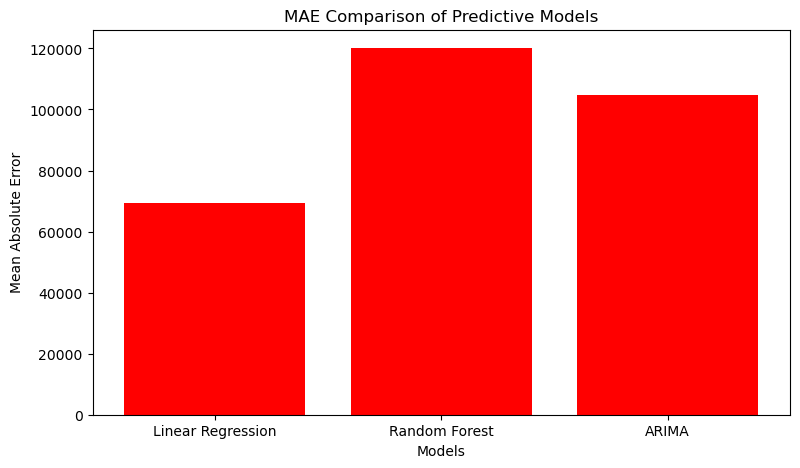

In [192]:
models = [
    "Linear Regression",
    "Random Forest",
    "ARIMA"
]

mae_values = [
    69412.58,
    120120.44,
    104878.25
]

plt.figure(figsize=(9, 5))

plt.bar(models, mae_values , color= "red")

plt.title("MAE Comparison of Predictive Models")
plt.xlabel("Models")
plt.ylabel("Mean Absolute Error")

plt.show()

In [198]:
# Build ARIMA model using complete historical data
final_arima_model = ARIMA(sales, order=(1, 1, 1))

# Train model
final_arima_result = final_arima_model.fit()

# Forecast next 4 weeks
future_sales = final_arima_result.forecast(steps=4)

# Generate future dates
future_dates = pd.date_range(
    start=sales.index[-1] + pd.Timedelta(weeks=1),
    periods=4,
    freq="W-FRI"
)

# Create forecast table
forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Weekly_Sales": future_sales.values
})

print(forecast_df)

        Date  Predicted_Weekly_Sales
0 2012-11-02            1.538713e+06
1 2012-11-09            1.556450e+06
2 2012-11-16            1.563433e+06
3 2012-11-23            1.566182e+06


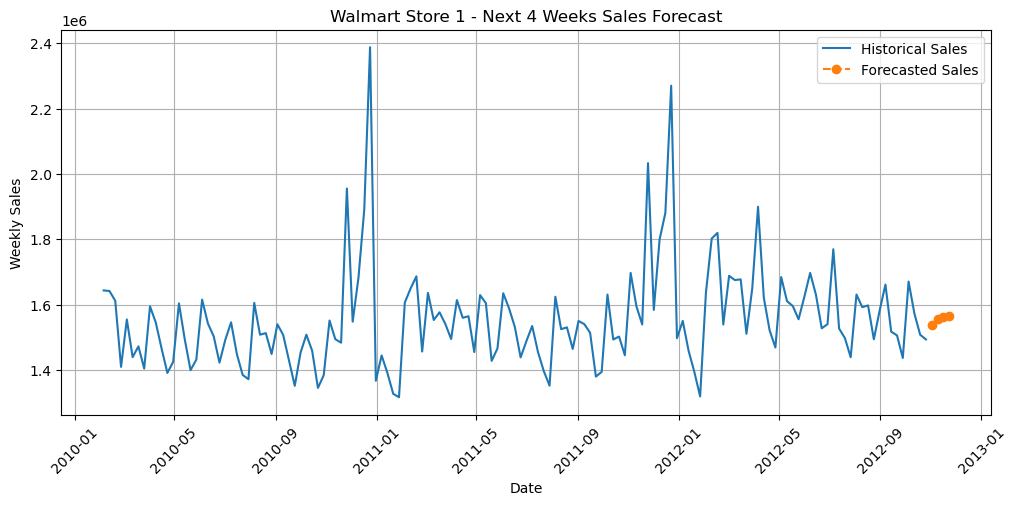

In [204]:
import matplotlib.pyplot as plt

plt.figure(figsize = (12 ,5))

plt.plot(sales.index , sales.values , label = "Historical Sales")

plt.plot(
    future_dates , 
    future_sales.values,
    marker = "o" , 
    linestyle = "--" , 
    label = "Forecasted Sales"
)

plt.title("Walmart Store 1 - Next 4 Weeks Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.xticks(rotation = 45)
plt.grid(True)
plt.show()

In [206]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "ARIMA"
    ],
    "MAE": [
        69412.58,
        120120.44,
        104878.25
    ],
    "RMSE": [
        84650.61,
        140513.82,
        122601.63
    ],
    "R2 Score": [
        -0.0803,
        -1.9765,
        -1.3684
    ]
})

print(comparison)

               Model        MAE       RMSE  R2 Score
0  Linear Regression   69412.58   84650.61   -0.0803
1      Random Forest  120120.44  140513.82   -1.9765
2              ARIMA  104878.25  122601.63   -1.3684
